# 1 · The Rydberg blockade

**One atom, two atoms, no double excitation.** A laser drives each rubidium atom between its
ground state |g⟩ and a huge Rydberg state |r⟩. Two Rydberg atoms repel with a van der Waals
interaction U = C₆/r⁶. Closer than the *blockade radius*, U is far larger than the drive Ω,
so the pair can share one excitation but never hold two. That single rule is the
entangling resource behind everything else in this project.

In one register we place three things, far enough apart that they don't talk to each other:

* **A**, two atoms 5 µm apart: blockaded (U ≈ 55 rad/µs ≫ Ω)
* **B**, two atoms 10 µm apart: almost independent (U ≈ 0.9 rad/µs < Ω)
* **C**, a single atom for reference

and drive them all with one resonant pulse of increasing length.

In [1]:
# Setup: needs the "Python 3 [Pasqal]" kernel (qBraid environment "Pasqal (Pulser)").
import sys, json, pathlib
try:
    import pulser, qbraid
except ImportError:
    raise SystemExit('Switch the kernel to "Python 3 [Pasqal]" (Kernel > Change Kernel), '
                     'or install the environment with: qbraid envs install pasqal_js2dr3')
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np
import matplotlib.pyplot as plt
from pasqal_atoms import *
print("pulser", pulser.__version__, "| qbraid", qbraid.__version__)

pulser 1.10.0 | qbraid 0.13.1


### Where to run

| `TARGET` | Runs on | Cost | Atoms |
|---|---|---|---|
| `"local"` | exact simulation on this machine (`pulser-simulation`) | free | up to ~12 |
| `"emu"` | Pasqal's **EMU_FREE** cloud emulator, through qBraid | free | up to 12 |
| `"qpu"` | Pasqal's **FRESNEL_CAN1** neutral-atom QPU, through qBraid | per minute of QPU time | up to 100 |

The sequences are built on FRESNEL_CAN1's real device specs and calibrated layout, so the
*same* object runs on all three. Start with `"emu"`; switch to `"qpu"` only after the
emulator result looks right and you have checked the estimate below.

A spacing 5.0 µm, U = 55.4 rad/µs
B spacing 10.0 µm, U = 0.87 rad/µs
blockade radius at this Ω: 7.2 µm


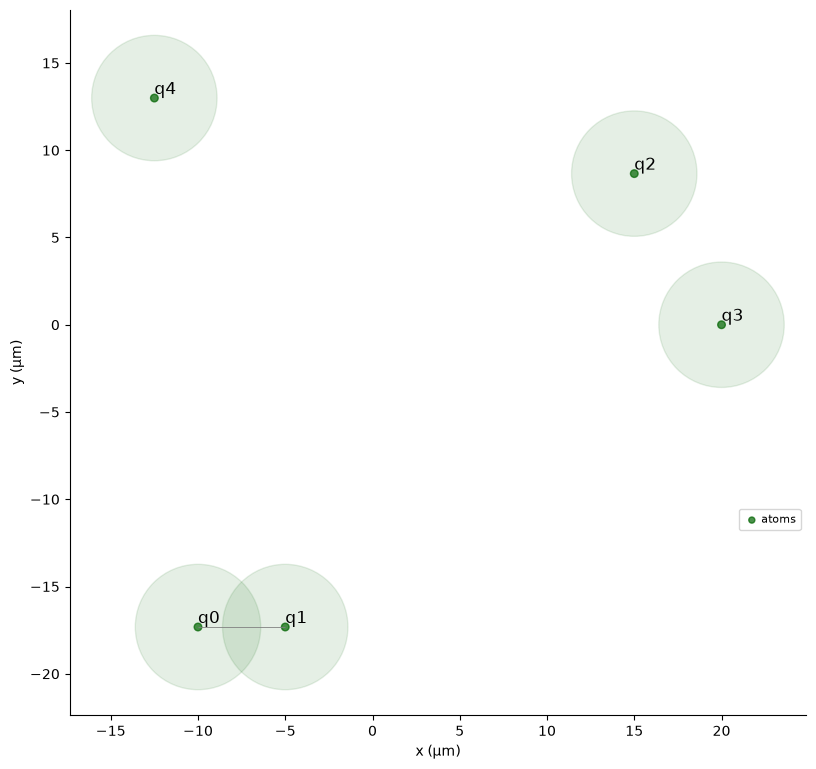

In [2]:
TARGET = "emu"        # "local", "emu" or "qpu"
SHOTS = 500
OMEGA = 2 * np.pi * 1.0   # Rabi frequency, rad/µs (1 MHz)

TRAPS = [9, 18, 56, 59, 8]        # A = (9, 18) at 5 µm, B = (56, 59) at 10 µm, C = 8
reg = layout_register(TRAPS)
pos = trap_positions()
print("A spacing %.1f µm, U = %.1f rad/µs" % (np.linalg.norm(pos[9] - pos[18]), interaction(5.0)))
print("B spacing %.1f µm, U = %.2f rad/µs" % (np.linalg.norm(pos[56] - pos[59]), interaction(10.0)))
print("blockade radius at this Ω: %.1f µm" % blockade_radius(OMEGA))
reg.draw(blockade_radius=blockade_radius(OMEGA), draw_half_radius=True)

In [3]:
DURATIONS = [16, 100, 200, 300, 400, 500, 600, 700, 800, 900, 1000, 1200]   # ns
seqs = [resonant_pulse(reg, t, OMEGA) for t in DURATIONS]
for s in seqs:
    check_for_qpu(s)          # raises if FRESNEL_CAN1 would reject it
print(len(seqs), "sequences pass the FRESNEL_CAN1 check")

12 sequences pass the FRESNEL_CAN1 check


In [4]:
counts = run_many(seqs, target=TARGET, shots=SHOTS)
exact = run_many(seqs, target="local", shots=2000)   # noiseless reference, free

submitted:
  pasqal:pasqal:sim:emu-free-8802-qjob-6b08e6f71cb75925982638b7
  pasqal:pasqal:sim:emu-free-8802-qjob-6b08e6f81cb75925982638c3
  pasqal:pasqal:sim:emu-free-8802-qjob-6b08e6fa1cb75925982638d3
  pasqal:pasqal:sim:emu-free-8802-qjob-6b08e6fb1cb75925982638e4
  pasqal:pasqal:sim:emu-free-8802-qjob-6b08e6fd1cb75925982638f2
  pasqal:pasqal:sim:emu-free-8802-qjob-6b08e6fe1cb75925982638fd
  pasqal:pasqal:sim:emu-free-8802-qjob-6b08e6ff1cb7592598263907
  pasqal:pasqal:sim:emu-free-8802-qjob-6b08e7001cb759259826390f
  pasqal:pasqal:sim:emu-free-8802-qjob-6b08e7011cb759259826391a
  pasqal:pasqal:sim:emu-free-8802-qjob-6b08e7021cb7592598263921
  pasqal:pasqal:sim:emu-free-8802-qjob-6b08e7021cb7592598263928
  pasqal:pasqal:sim:emu-free-8802-qjob-6b08e7031cb759259826392c


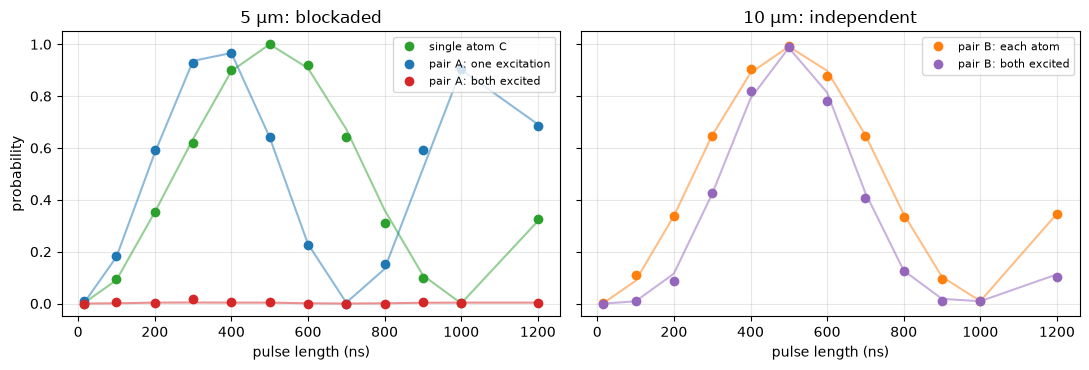

In [5]:
def summary(c):
    p = densities(c)
    return {"A_any": prob(c, lambda b: "1" in b[0:2]), "A_both": prob(c, lambda b: b[0:2] == "11"),
            "B_both": prob(c, lambda b: b[2:4] == "11"), "B_each": p[2:4].mean(), "C": p[4]}
S, X = [summary(c) for c in counts], [summary(c) for c in exact]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for key, lab, col in [("C", "single atom C", "C2"), ("A_any", "pair A: one excitation", "C0"),
                      ("A_both", "pair A: both excited", "C3")]:
    ax[0].plot(DURATIONS, [x[key] for x in X], "-", color=col, alpha=.5)
    ax[0].plot(DURATIONS, [s[key] for s in S], "o", color=col, label=lab)
ax[0].set(title="5 µm: blockaded", xlabel="pulse length (ns)", ylabel="probability")
for key, lab, col in [("B_each", "pair B: each atom", "C1"), ("B_both", "pair B: both excited", "C4")]:
    ax[1].plot(DURATIONS, [x[key] for x in X], "-", color=col, alpha=.5)
    ax[1].plot(DURATIONS, [s[key] for s in S], "o", color=col, label=lab)
ax[1].set(title="10 µm: independent", xlabel="pulse length (ns)")
for a in ax: a.legend(fontsize=8); a.grid(alpha=.3)
plt.tight_layout()

**What to see.** The single atom flops with period 2π/Ω = 1000 ns. Pair A never has both
atoms excited, and its one shared excitation oscillates √2 times faster (period ≈ 707 ns):
the pair is in the entangled state (|gr⟩ + |rg⟩)/√2. Pair B behaves like two copies of
atom C: P(both) = P(one)². Dots are the cloud emulator; faint lines are the exact local
simulation.

In [6]:
fit = lambda key: float(np.mean([abs(s[key] - x[key]) for s, x in zip(S, X)]))
result = {"chapter": 1, "traps": TRAPS, "omega": OMEGA, "durations": DURATIONS, "target": TARGET,
          "shots": SHOTS, "emu": S, "exact": X,
          "max_A_both": max(s["A_both"] for s in S),
          "mean_abs_dev": {k: fit(k) for k in S[0]}}
(ROOT / "results").mkdir(exist_ok=True)
json.dump(result, open(ROOT / "results" / "01_blockade.json", "w"), indent=1)
print("largest P(A both excited):", result["max_A_both"])
print("mean |emulator - exact|:", {k: round(v, 3) for k, v in result["mean_abs_dev"].items()})

largest P(A both excited): 0.016
mean |emulator - exact|: {'A_any': 0.011, 'A_both': 0.002, 'B_both': 0.011, 'B_each': 0.008, 'C': 0.011}


## Run it on the QPU

Everything above ran on the free emulator. The same sequences run unchanged on FRESNEL_CAN1.
QPU time is billed per minute and jobs wait in Pasqal's queue (hours to days), so:

1. Check the estimate (credits; 1 credit = USD 0.01). It is based on ~1.2 s of QPU time per shot.
2. Set `CONFIRM_QPU = True` and run the cell. It submits and prints the job IDs; it does not wait.
3. Come back later: `qbraid jobs get <id>`, or the Lab's **Quantum Jobs** panel.

In [7]:
CONFIRM_QPU = False
QPU_DURATIONS, QPU_SHOTS = [350, 700], 50     # half and full collective period: enough to see blockade
print(qpu_estimate(QPU_SHOTS, n_jobs=len(QPU_DURATIONS)))
if CONFIRM_QPU:
    jobs = [submit(resonant_pulse(reg, t, OMEGA), "qpu", QPU_SHOTS, confirm_qpu=True)
            for t in QPU_DURATIONS]
    print("QPU job IDs:", *[j.id for j in jobs], sep="\n  ")
    # later: qpu_counts = wait(jobs, timeout=7 * 24 * 3600)

{'credits_per_minute': 6358.0, 'est_qpu_seconds': 120.0, 'est_credits': 12716.0, 'est_usd': 127.16}
